In [2]:
import pygeoinf as inf 
import numpy as np
import pandas as pd
import time
from typing import List, Any
import matplotlib.pyplot as plt
from pygeoinf.symmetric_space.plane import plot as plot_plane
from aux_plane import build_water_mass_forward_operator, build_mass_conservation_subspace
from data_helper import load_em_matrix, get_measurement_locations, restrict_to_domain

In [3]:
# --- Choose the parameters for the model space ---
kmax = 100
order = 2
scale = 5
lat_min = -70
lat_max = -30
lon_min = 0
lon_max = 180

# --- Load the EM matrix and the measurement locations inside the domain ---
mat, names = load_em_matrix()
all_lats, all_lons = get_measurement_locations()
lats, lons = restrict_to_domain(all_lats, all_lons, lat_min, lat_max, lon_min, lon_max)
n_points = len(lats)
print(f"{n_points} measurements inside the domain")

# --- TEMPORARY: drop NADW until its .npy file is corrected ---
# NADW_EMs.npy is currently identical to AABW_EMs.npy, so the two are
# indistinguishable. The independent classification in SO_data_4_dan.csv gives
# NADW far less weight (mean fraction 0.007 vs 0.089 for AABW), so drop NADW.
nadw_idx = names.index("NADW")
mat = np.delete(mat, nadw_idx, axis=1)
names = names[:nadw_idx] + names[nadw_idx + 1:]

# --- TEMPORARY: drop the silicate row (row 5) until we have silicate data ---
# SO_data_4_dan.csv has no silicate column.
silicate_row = 5
mat = np.delete(mat, silicate_row, axis=0)

print(f"EM matrix after removals: {mat.shape[0]} observables x {mat.shape[1]} water masses {names}")

# --- Set the standard deviation for the prior distributions of the mass fractions ---
# Imposing mass conservation lowers the pointwise std of each fraction to
# mass_fraction_std * sqrt(1 - 1 / n_water_masses), about 0.94 * 0.3 for 8 masses.
mass_fraction_std = 0.3

# --- Set the data error standard deviations, in the row order of mat ---
# Roughly GO-SHIP-quality bottle/CTD accuracies.
temp_std = 0.02         # potential temperature, degC
salinity_std = 0.02     # absolute salinity, g/kg
oxygen_std = 20.0         # oxygen, umol/kg (~1%)
nitrate_std = 3.0        # nitrate, umol/kg (~1%)
phosphate_std = 0.2     # phosphate, umol/kg (~1%)
silicate_std = 10.0       # silicate, umol/kg (~1-2%)
alkalinity_std = 30.0     # total alkalinity, umol/kg

# Silicate is left out of both lists while its row is removed from mat.
obs_names = ["temp", "salinity", "oxygen", "nitrate", "phosphate", "alkalinity"]
obs_stds = [
    temp_std,
    salinity_std,
    oxygen_std,
    nitrate_std,
    phosphate_std,
    # silicate_std,
    alkalinity_std,
]
assert len(obs_stds) == mat.shape[0], f"Need {mat.shape[0]} error stds, got {len(obs_stds)}"

188 measurements inside the domain
EM matrix after removals: 6 observables x 8 water masses ['AABW', 'AAIW', 'AASW', 'CDW', 'HSSW', 'SAMW1', 'SAMW2', 'STCW']


In [4]:
# --- Build the forward operator ---
forward_operator = build_water_mass_forward_operator(
    mat,
    lats,
    lons,
    kmax,
    order,
    scale,
    lat_min,
    lat_max,
    lon_min,
    lon_max    
)

model_space = forward_operator.domain
data_space = forward_operator.codomain
n_water_masses = model_space.number_of_subspaces
n_obs_types = data_space.number_of_subspaces

# --- Set up the forward problem ---
# Independent errors at each point, with one standard deviation per observable.
data_space_component = data_space.subspaces[0]
data_error_measures = [
    inf.GaussianMeasure.from_standard_deviation(data_space_component, obs_std)
    for obs_std in obs_stds
]
joint_data_error_measure = inf.GaussianMeasure.from_direct_sum(data_error_measures)

forward_problem = inf.LinearForwardProblem(
    forward_operator,
    data_error_measure=joint_data_error_measure,
)
print(f"Forward problem: [{forward_problem.model_space.dim} -> {forward_problem.data_space.dim}]")

# --- Set up the prior measure ---
model_space_component = model_space.subspaces[0]
prior_expectation = model_space_component.zero + 1.0 / n_water_masses #to make sure it is a field
single_prior_measure = model_space_component.point_value_scaled_sobolev_kernel_gaussian_measure(
    2,
    scale,
    expectation=prior_expectation,
    std=mass_fraction_std,
)
joint_prior_measure = inf.GaussianMeasure.from_direct_sum(
    [single_prior_measure] * n_water_masses
)

# --- Impose conservation of mass (fractions sum to one everywhere) ---
# Every water mass has the same prior, so the geometric projection onto the
# subspace is exact Bayesian conditioning.
mass_conservation_subspace = build_mass_conservation_subspace(model_space)
constrained_prior_measure = mass_conservation_subspace.condition_gaussian_measure(
    joint_prior_measure,
    geometric=True,
)

# --- Generate a true model and synthetic data from the constrained prior ---
np.random.seed(76)
true_model, data = forward_problem.synthetic_model_and_data(constrained_prior_measure)

Forward problem: [320000 -> 1128]


In [5]:
#=======================================================================
# Perform the Bayesian inversion to get the posterior measure
#=======================================================================

# The data space is small (n_points * n_obs_types) while the model space is
# large, so we solve in the data-space formalism. The normal operator
# A Q A* + R is assembled as a dense matrix (one column per datum, built in
# parallel) and Cholesky-factorised once. This is exact, unaffected by the very
# different error scales of the observables (which cripple CG), and makes every
# later solve for the posterior mean and samples cheap.
solver = inf.CholeskySolver(galerkin=True, parallel=True, n_jobs=32)

bayesian_inversion = inf.LinearBayesianInversion(
    forward_problem,
    constrained_prior_measure,
)

start_time = time.perf_counter()
model_posterior_measure = bayesian_inversion.model_posterior_measure(
    data,
    solver,
)
posterior_mean = model_posterior_measure.expectation
print(f"Posterior computed in {time.perf_counter() - start_time:.1f} s (data dimension {data_space.dim})")

Posterior computed in 28.7 s (data dimension 1128)


In [6]:
# --- Estimate the pointwise posterior standard deviation from samples ---
# Each sample reuses the Cholesky factor, so this costs one forward and adjoint
# application per sample.
n_samples = 5
start_time = time.perf_counter()
posterior_samples = [model_posterior_measure.sample() for _ in range(n_samples)]
posterior_std = [
    np.std([sample[j] for sample in posterior_samples], axis=0)
    for j in range(n_water_masses)
]
print(f"{n_samples} posterior samples in {time.perf_counter() - start_time:.1f} s")

5 posterior samples in 0.4 s


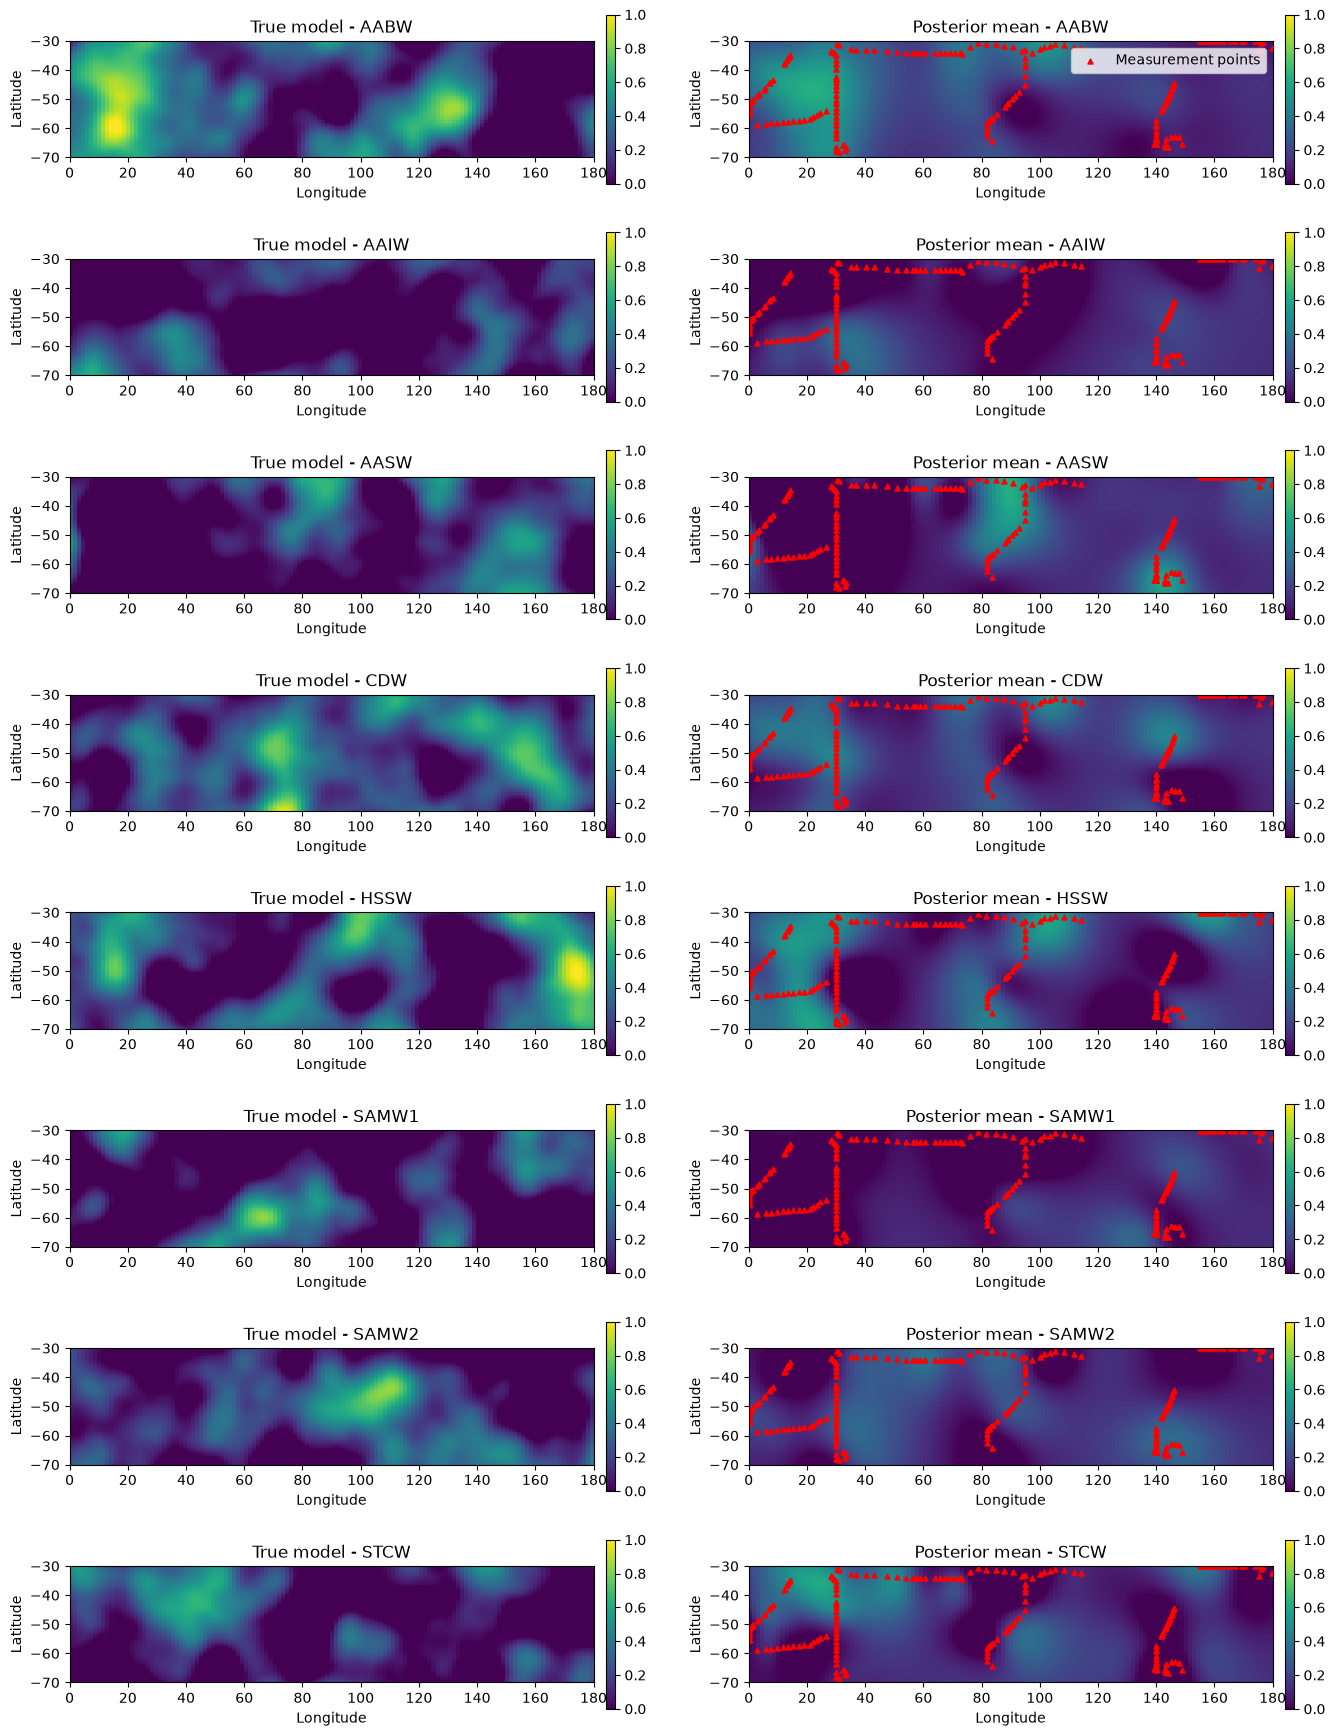

In [7]:
#=======================================================================
# Plot the true model and posterior mean for each water mass
#=======================================================================

fig, axes = plt.subplots(n_water_masses, 2, figsize=(14, 2.2 * n_water_masses))
colorbar_kwargs = {"orientation": "vertical", "shrink": 0.9, "pad": 0.02}

for i, name in enumerate(names):

    # --- True model ---
    ax = axes[i, 0]
    plot_plane(
        model_space_component,
        true_model[i],
        ax=ax,
        cmap="viridis",
        vmin=0,
        vmax=1,
        colorbar=True,
        colorbar_kwargs=colorbar_kwargs,
    )
    ax.set_title(f"True model - {name}")

    # --- Posterior mean, with the measurement locations ---
    ax = axes[i, 1]
    plot_plane(
        model_space_component,
        posterior_mean[i],
        ax=ax,
        cmap="viridis",
        vmin=0,
        vmax=1,
        colorbar=True,
        colorbar_kwargs=colorbar_kwargs,
    )
    ax.scatter(
        lons,
        lats,
        c="red",
        marker="^",
        s=13,
        label="Measurement points",
    )
    ax.set_title(f"Posterior mean - {name}")

axes[0, 1].legend(loc="upper right")

for ax in axes.flat:
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()